In [ ]:
!pip install -q gdown
!pip install -q optuna

In [ ]:
import os
import random
import json as json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import optuna
import joblib

from google.colab import drive

# Reproducibility seeds
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
print(f"Random seeds fixed to {RANDOM_SEED}")


Random seeds fixed to 42


In [ ]:
# Mount Google Drive for data persistence
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Create persistent output directory on Drive
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens"
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
print(f"Drive mounted. Outputs will be saved to: {DRIVE_OUTPUT_DIR}")


Drive mounted. Outputs will be saved to: /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens


## Data Loading

In [ ]:
def get_model_data_v2(path="/content/labelled.csv", relative=True, roll=True, natural_only=False):
    """
    Enhanced model data loader with temporal rolling statistics,
    angle magnitude symmetries, and eye gaze tracking.
    """
    need = {
        "session", "participant", "t_ms", "calib", "face", "usable", "scripted", "label",
        "yaw", "pitch", "roll", "eyeBlinkLeft", "eyeBlinkRight",
        "eyeLookDownLeft", "eyeLookDownRight", "eyeLookInLeft", "eyeLookOutLeft"
    }
    raw = pd.read_csv(path, usecols=lambda c: c in need)

    # Calibration baseline subtraction
    if relative:
        base = (raw[(raw["calib"] == 1) & (raw["face"] == 1)]
                .groupby("session")[["yaw", "pitch"]].median().add_suffix("_base"))
        raw = raw.join(base, on="session")
        raw["yaw"] -= raw["yaw_base"].fillna(0)
        raw["pitch"] -= raw["pitch_base"].fillna(0)

    if natural_only:
        raw = raw[~raw["scripted"]]

    # Filter usable frames with a detected face
    d = raw[raw["usable"] & (raw["face"] == 1)].copy()
    d = d.sort_values(by=["session", "t_ms"]).reset_index(drop=True)

    # FEATURE ENGINEERING: Angles & Symmetries
    out = pd.DataFrame()
    out["yaw"] = d["yaw"]
    out["pitch"] = d["pitch"]
    out["abs_yaw"] = d["yaw"].abs()          # Symmetrical left/right turns
    out["abs_pitch"] = d["pitch"].abs()      # Symmetrical up/down tilt
    out["pose_magnitude"] = np.sqrt(d["yaw"]**2 + d["pitch"]**2)  # Total angular deviation

    if roll:
        out["roll"] = d["roll"]
        out["abs_roll"] = d["roll"].abs()

    # FEATURE ENGINEERING: Eye Closure
    out["blink_left"] = d["eyeBlinkLeft"]
    out["blink_right"] = d["eyeBlinkRight"]
    out["blink_max"] = d[["eyeBlinkLeft", "eyeBlinkRight"]].max(axis=1)

    # TEMPORAL CONTEXT: 1-Second Rolling Eye Closure (Blinks vs Naps)
    out["session"] = d["session"]
    out["blink_rolling_mean"] = (
        out.groupby("session")["blink_max"]
        .transform(lambda s: s.rolling(window=15, min_periods=1).mean())
    )
    out.drop(columns=["session"], inplace=True)

    # FEATURE ENGINEERING: Eye Gaze Tracking
    if "eyeLookDownLeft" in d.columns and "eyeLookDownRight" in d.columns:
        out["v_gaze"] = (d["eyeLookDownLeft"] + d["eyeLookDownRight"]) / 2.0
    if "eyeLookInLeft" in d.columns and "eyeLookOutLeft" in d.columns:
        out["h_gaze"] = np.abs(d["eyeLookInLeft"] - d["eyeLookOutLeft"])

    # Target & Subject
    out["label"] = d["label"].astype("int64")
    out["subject"] = d["participant"].astype(str)

    # Clean float types
    f_cols = [c for c in out.columns if out[c].dtype == "float64"]
    out[f_cols] = out[f_cols].astype("float32")
    out = out.dropna().reset_index(drop=True)

    print(f"Dataset Shape: {out.shape} | Lost Focus Ratio: {out['label'].mean():.1%} | Subjects: {out['subject'].nunique()}")
    return out

In [ ]:
# Path to dataset
data_path = "/content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/labelled.csv"

assert os.path.exists(data_path), f"File not found at: {data_path}"

# Load upgraded dataset
df = get_model_data_v2(path=data_path, relative=True, roll=True)
# pose only:     get_model_data(eyes="none", roll=True)
# for grace eval: get_model_data(keep_all=True)

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns.\n")
print("Columns in labelled.csv")
print(list(df.columns))

print("\nFirst 3 Rows")
display(df.head(3))

Dataset Shape: (51017, 15) | Lost Focus Ratio: 29.5% | Subjects: 12
Loaded 51,017 rows and 15 columns.

Columns in labelled.csv
['yaw', 'pitch', 'abs_yaw', 'abs_pitch', 'pose_magnitude', 'roll', 'abs_roll', 'blink_left', 'blink_right', 'blink_max', 'blink_rolling_mean', 'v_gaze', 'h_gaze', 'label', 'subject']

First 3 Rows


,yaw,pitch,abs_yaw,abs_pitch,pose_magnitude,roll,abs_roll,blink_left,blink_right,blink_max,blink_rolling_mean,v_gaze,h_gaze,label,subject
0,-2.701,6.650,2.701,6.650,7.177597,3.752,3.752,0.0223,0.0078,0.0223,0.022300,0.26705,0.1961,0,P01
1,-2.212,6.822,2.212,6.822,7.171655,3.425,3.425,0.0285,0.0093,0.0285,0.025400,0.26645,0.1844,0,P01
2,-2.051,6.832,2.051,6.832,7.133220,3.251,3.251,0.0268,0.0089,0.0268,0.025867,0.24880,0.1912,0,P01


In [ ]:
# Dynamically extract ALL features
feature_cols = [c for c in df.columns if c not in ["label", "subject"]]
print(f"Features ({len(feature_cols)}): {feature_cols}")

X = df[feature_cols].values
y = df["label"].values.astype(int)
groups = df["subject"].values
classes = np.unique(y)

print(f"Total samples: {len(df):,} across {len(np.unique(groups))} unique subjects.")
print(f"Class balance: Focused (0) = {(y == 0).mean():.1%}, Lost Focus (1) = {(y == 1).mean():.1%}")

Features (13): ['yaw', 'pitch', 'abs_yaw', 'abs_pitch', 'pose_magnitude', 'roll', 'abs_roll', 'blink_left', 'blink_right', 'blink_max', 'blink_rolling_mean', 'v_gaze', 'h_gaze']
Total samples: 51,017 across 12 unique subjects.
Class balance: Focused (0) = 70.5%, Lost Focus (1) = 29.5%


## Data Spliting

In [ ]:
unique_subjects = np.sort(df["subject"].unique())
print(f"Total unique subjects ({len(unique_subjects)}): {list(unique_subjects)}\n")

Total unique subjects (12): ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P09', 'P10', 'P11', 'P12', 'P13', 'P14']



In [ ]:
shuffled_subjects = np.random.permutation(unique_subjects)

# 8 Train / 2 Val / 2 Test
test_subjects  = list(shuffled_subjects[:2])
val_subjects   = list(shuffled_subjects[2:4])
train_subjects = list(shuffled_subjects[4:])

# Combined development pool (Train + Val) for GroupKFold
train_val_subjects = train_subjects + val_subjects

# Verify Zero data leakage
assert len(set(train_subjects) & set(val_subjects)) == 0, "Leakage: Subject in both Train and Val!"
assert len(set(train_subjects) & set(test_subjects)) == 0, "Leakage: Subject in both Train and Test!"
assert len(set(val_subjects) & set(test_subjects)) == 0, "Leakage: Subject in both Val and Test!"

In [ ]:
# Filter Dataframes by Assigned Subjects
train_df = df[df["subject"].isin(train_subjects)].reset_index(drop=True)
val_df   = df[df["subject"].isin(val_subjects)].reset_index(drop=True)
test_df  = df[df["subject"].isin(test_subjects)].reset_index(drop=True)
train_val_df   = df[df["subject"].isin(train_val_subjects)].reset_index(drop=True)


In [ ]:
# Raw feature arrays
X_train = train_df[feature_cols].values
y_train = train_df["label"].values

X_val = val_df[feature_cols].values
y_val = val_df["label"].values

X_test = test_df[feature_cols].values
y_test = test_df["label"].values

X_train_val = train_val_df[feature_cols].values
y_train_val = train_val_df["label"].values
groups_train_val = train_val_df["subject"].values

# Combined Dev arrays (for GroupKFold cross-validation)
X_train_val = train_val_df[feature_cols].values
y_train_val = train_val_df["label"].values
groups_train_val = train_val_df["subject"].values

In [ ]:
split_summary = pd.DataFrame([
    {
        "Split": "Train",
        "Subjects": f"{len(train_subjects)} {train_subjects}",
        "Rows": f"{len(train_df):,}",
        "% of Total": f"{len(train_df)/len(df):.1%}",
        "Focused (0)": f"{(y_train == 0).mean():.1%}",
        "Lost Focus (1)": f"{(y_train == 1).mean():.1%}"
    },
    {
        "Split": "Validation",
        "Subjects": f"{len(val_subjects)} {val_subjects}",
        "Rows": f"{len(val_df):,}",
        "% of Total": f"{len(val_df)/len(df):.1%}",
        "Focused (0)": f"{(y_val == 0).mean():.1%}",
        "Lost Focus (1)": f"{(y_val == 1).mean():.1%}"
    },
    {
        "Split": "Held-Out Test",
        "Subjects": f"{len(test_subjects)} {test_subjects}",
        "Rows": f"{len(test_df):,}",
        "% of Total": f"{len(test_df)/len(df):.1%}",
        "Focused (0)": f"{(y_test == 0).mean():.1%}",
        "Lost Focus (1)": f"{(y_test == 1).mean():.1%}"
    }
])


print(" Subject-Independent Data Split Summary \n")

display(split_summary)
print(f"\n Features ({len(feature_cols)}) preserved across all splits.")

 Subject-Independent Data Split Summary 



,Split,Subjects,Rows,% of Total,Focused (0),Lost Focus (1)
0,Train,"8 ['P06', 'P03', 'P02', 'P14', 'P05', 'P10', '...","35,575",69.7%,71.1%,28.9%
1,Validation,"2 ['P01', 'P11']","8,075",15.8%,73.9%,26.1%
2,Held-Out Test,"2 ['P13', 'P12']","7,367",14.4%,63.9%,36.1%



 Features (13) preserved across all splits.


## Train & Compare Multiple Models
We benchmark four diverse architectures:
- Logistic Regression (Linear baseline, highly interpretable)
- Random Forest (Tree-based ensemble, non-linear)
- HistGradientBoosting (Fast gradient-boosted trees, similar to LightGBM/XGBoost)
- Multi-Layer Perceptron (MLP) (Small neural network)

In [ ]:
# Define baseline models
# Format: (classifier, x_dev, x_train, x_val, x_test)
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=4, random_state=RANDOM_SEED, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("clf", HistGradientBoostingClassifier(max_iter=100, max_depth=6, min_samples_leaf=20, random_state=RANDOM_SEED))
    ]),
    "Neural Network (MLP)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.01, max_iter=250, early_stopping=True, random_state=RANDOM_SEED))
    ])
}

In [ ]:
results = []
trained_models = {}

n_dev_subjects = len(np.unique(groups_train_val))
n_splits = min(4, n_dev_subjects)
gkf = GroupKFold(n_splits=n_splits)

print(f"Running {n_splits}-fold GroupKFold Cross-Validation across {n_dev_subjects} development subjects...\n")

for name, pipe in models.items():
    print(f"Evaluating {name}...")

    # Subject-level cross-validation on dev set
    cv_scores = cross_val_score(
        pipe, X_train_val, y_train_val,
        groups=groups_train_val,
        cv=gkf,
        scoring="f1_macro"
    )
    cv_val_f1 = cv_scores.mean()
    cv_val_std = cv_scores.std()

    # Fit pipeline on full dev set
    pipe.fit(X_train_val, y_train_val)
    trained_models[name] = pipe

    # Train performance
    tr_preds = pipe.predict(X_train_val)
    tr_f1    = f1_score(y_train_val, tr_preds, average="macro")

    # Held-out test evaluation
    te_preds = pipe.predict(X_test)
    te_acc   = accuracy_score(y_test, te_preds)
    te_f1    = f1_score(y_test, te_preds, average="macro")
    try:
        te_probs = pipe.predict_proba(X_test)[:, 1]
        te_auc   = roc_auc_score(y_test, te_probs)
    except:
        te_auc   = np.nan

    results.append({
        "Model": name,
        "Train F1": tr_f1,
        "Val F1 (CV)": cv_val_f1,
        "Val F1 (Std)": cv_val_std,
        "Overfit Gap (Tr - Val)": tr_f1 - cv_val_f1,
        "Test Acc": te_acc,
        "Test F1": te_f1,
        "Test AUC": te_auc
    })

results_df = pd.DataFrame(results).sort_values(by="Test F1", ascending=False).reset_index(drop=True)

display(
    results_df.style
    .highlight_max(subset=["Val F1 (CV)", "Test F1"], color="green")
    .format({
        "Train F1": "{:.3f}", "Val F1 (CV)": "{:.3f}", "Val F1 (Std)": "±{:.3f}",
        "Overfit Gap (Tr - Val)": "{:+.3f}", "Test Acc": "{:.3f}", "Test F1": "{:.3f}", "Test AUC": "{:.3f}"
    })
)


Running 4-fold GroupKFold Cross-Validation across 10 development subjects...

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating Neural Network (MLP)...


,Model,Train F1,Val F1 (CV),Val F1 (Std),Overfit Gap (Tr - Val),Test Acc,Test F1,Test AUC
0,Random Forest,0.931,0.785,±0.035,+0.146,0.857,0.841,0.922
1,Gradient Boosting,0.940,0.796,±0.035,+0.144,0.847,0.832,0.906
2,Neural Network (MLP),0.958,0.763,±0.041,+0.195,0.820,0.800,0.859
3,Logistic Regression,0.813,0.772,±0.044,+0.041,0.814,0.787,0.894


In [ ]:
# Output directory setup for baselines
baseline_dir = os.path.join(DRIVE_OUTPUT_DIR, "baseline")
os.makedirs(baseline_dir, exist_ok=True)

print("SAVING BASELINE PIPELINES & MANIFEST TO GOOGLE DRIVE")

manifest = {}

# Save each trained baseline pipeline
for model_name, pipe in trained_models.items():
    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    save_path = os.path.join(baseline_dir, f"{safe_name}.pkl")

    # Save the complete pipeline
    joblib.dump(pipe, save_path)

    # Check if an internal StandardScaler is bundled
    has_scaler = "scaler" in pipe.named_steps if hasattr(pipe, "named_steps") else False
    tag = "scaler bundled inside" if has_scaler else "raw features"

    print(f"  [{tag:>23}]  {model_name:<25} -> {save_path}")

    manifest[model_name] = {
        "file": save_path,
        "self_contained_pipeline": True,
        "has_internal_scaler": has_scaler,
        "input_features": feature_cols
    }

# Save baseline performance table (CSV)
baseline_csv = os.path.join(baseline_dir, "baseline_results.csv")
results_df.to_csv(baseline_csv, index=False)
print(f"\nSaved Baseline Results -> {baseline_csv}")

# Save feature order and schema manifest (JSON)
manifest_path = os.path.join(baseline_dir, "baseline_manifest.json")
with open(manifest_path, "w") as f:
    json.dump({
        "num_features": len(feature_cols),
        "features_in_order": feature_cols,
        "models": manifest
    }, f, indent=2)
print(f"Saved Baseline Manifest -> {manifest_path}")


SAVING BASELINE PIPELINES & MANIFEST TO GOOGLE DRIVE
  [  scaler bundled inside]  Logistic Regression       -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Logistic_Regression.pkl
  [           raw features]  Random Forest             -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Random_Forest.pkl
  [           raw features]  Gradient Boosting         -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Gradient_Boosting.pkl
  [  scaler bundled inside]  Neural Network (MLP)      -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/Neural_Network_MLP.pkl

Saved Baseline Results -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/baseline_results.csv
Saved Baseline Manifest -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/baseline/baseline_manifest.json


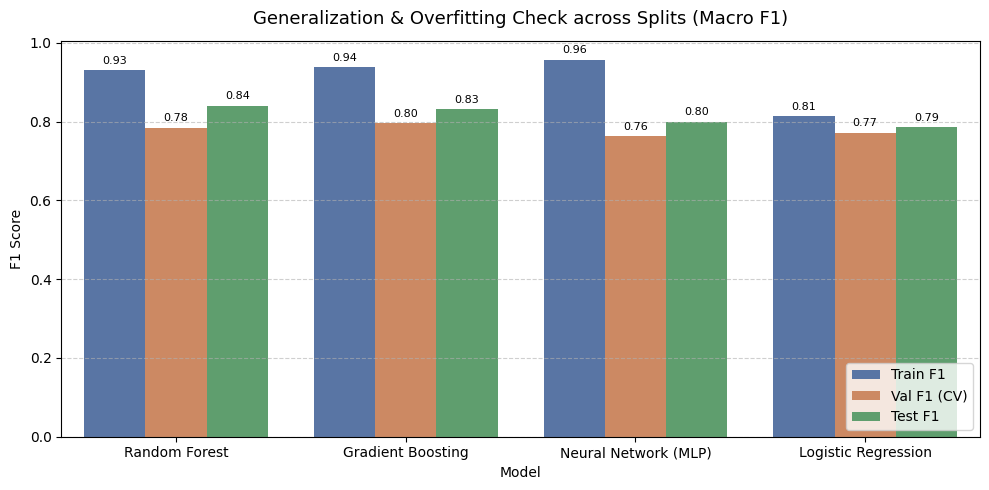

In [ ]:
# Melt dataframe for easy seaborn plotting
plot_df = results_df.melt(
    id_vars=["Model"],
    value_vars=["Train F1", "Val F1 (CV)", "Test F1"],
    var_name="Split",
    value_name="F1 Score"
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, x="Model", y="F1 Score", hue="Split", palette=["#4c72b0", "#dd8452", "#55a868"])
plt.title("Generalization & Overfitting Check across Splits (Macro F1)", fontsize=13, pad=12)
# plt.ylim(0.6, 1.02)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')

# Add values above bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

## Hyperparameter Tuning

In [ ]:
# OBJECTIVE FUNCTIONS (Evaluated via GroupKFold)
cv_tuning = GroupKFold(n_splits=min(4, len(np.unique(groups_train_val))))

def objective_gb(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_iter": trial.suggest_int("max_iter", 60, 160, step=20),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 50),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 5.0, log=True),
        "random_state": RANDOM_SEED
    }
    clf = HistGradientBoostingClassifier(**params)
    scores = cross_val_score(clf, X_train_val, y_train_val, groups=groups_train_val, cv=cv_tuning, scoring="f1_macro")
    return scores.mean()

def objective_rf(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 60, 150, step=30),
        "max_depth": trial.suggest_int("max_depth", 6, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "random_state": RANDOM_SEED,
        "n_jobs": -1
    }
    clf = RandomForestClassifier(**params)
    scores = cross_val_score(clf, X_train_val, y_train_val, groups=groups_train_val, cv=cv_tuning, scoring="f1_macro")
    return scores.mean()

def objective_mlp(trial):
    hidden_options = [(64,), (64, 32), (128, 64)]
    idx = trial.suggest_int("hidden_idx", 0, len(hidden_options) - 1)
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=hidden_options[idx],
            activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
            alpha=trial.suggest_float("alpha", 1e-3, 1.0, log=True),
            learning_rate_init=trial.suggest_float("learning_rate_init", 1e-3, 1e-2, log=True),
            max_iter=250, early_stopping=True, random_state=RANDOM_SEED
        ))
    ])
    scores = cross_val_score(pipe, X_train_val, y_train_val, groups=groups_train_val, cv=cv_tuning, scoring="f1_macro")
    return scores.mean()

def objective_lr(trial):
    params = {
        "C": trial.suggest_float("C", 0.001, 100.0, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "max_iter": 1000,
        "random_state": RANDOM_SEED
    }
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(**params))
    ])
    scores = cross_val_score(pipe, X_train_val, y_train_val, groups=groups_train_val, cv=cv_tuning, scoring="f1_macro")
    return scores.mean()

In [ ]:
# Suppress debug logs from optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# RUN GROUP-KFOLD OPTIMIZATION STUDIES
# 25 trials * 4 subject-folds = 100 evaluations per architecture
studies = {
    "Gradient Boosting":    (objective_gb, 30),
    "Random Forest":        (objective_rf, 30),
    "Neural Network (MLP)": (objective_mlp, 30),
    "Logistic Regression":  (objective_lr, 30)
}

best_params = {}
for name, (obj, n_tr) in studies.items():
    print(f"--> Optimizing {name} ({n_tr} trials)...")
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    st.optimize(obj, n_trials=n_tr, show_progress_bar=True)
    best_params[name] = st.best_params
    print(f"    ✓ Best CV F1: {st.best_value:.4f}")

# Rebuild Tuned Pipelines
mlp_params = best_params["Neural Network (MLP)"].copy()
mlp_hidden = [(64,), (64, 32), (128, 64)][mlp_params.pop("hidden_idx")]

tuned_models = {
    "Gradient Boosting (Tuned)": Pipeline([
        ("clf", HistGradientBoostingClassifier(**best_params["Gradient Boosting"], random_state=RANDOM_SEED))
    ]),
    "Random Forest (Tuned)": Pipeline([
        ("clf", RandomForestClassifier(**best_params["Random Forest"], random_state=RANDOM_SEED, n_jobs=-1))
    ]),
    "Neural Network (Tuned)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=mlp_hidden, **mlp_params, max_iter=300, early_stopping=True, random_state=RANDOM_SEED))
    ]),
    "Logistic Regression (Tuned)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(**best_params["Logistic Regression"], max_iter=1000, random_state=RANDOM_SEED))
    ]),
}

print("\n✓ All 4 tuned pipelines constructed and ready for evaluation.")

--> Optimizing Gradient Boosting (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

    ✓ Best CV F1: 0.8116
--> Optimizing Random Forest (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

    ✓ Best CV F1: 0.7902
--> Optimizing Neural Network (MLP) (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

    ✓ Best CV F1: 0.8269
--> Optimizing Logistic Regression (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

    ✓ Best CV F1: 0.7832

✓ All 4 tuned pipelines constructed and ready for evaluation.


In [ ]:
final_results = []
trained_objects = {}

# Ensure classes array is defined
classes = np.unique(y_train_val)

print(f"Evaluating tuned models across {len(np.unique(groups_train_val))} development subjects and testing on held-out subjects...\n")

for name, item in tuned_models.items():
    print(f"--> Evaluating {name}...")

    # Flexible unpack: handles both Pipeline objects and legacy (clf, x_dev, x_tr, x_v, x_te) tuples
    if isinstance(item, tuple):
        clf, x_dev, _, _, x_te = item
    else:
        clf, x_dev, x_te = item, X_train_val, X_test

    # Subject-level GroupKFold Cross-Validation on development set
    cv_scores = cross_val_score(
        clf, x_dev, y_train_val,
        groups=groups_train_val,
        cv=cv_tuning,
        scoring="f1_macro"
    )
    v_f1  = cv_scores.mean()
    v_std = cv_scores.std()

    # Fit on full development set for maximum generalization
    clf.fit(x_dev, y_train_val)
    trained_objects[name] = clf

    # Train performance (fit check)
    tr_preds = clf.predict(x_dev)
    tr_f1    = f1_score(y_train_val, tr_preds, average="macro")

    # Evaluate on held-out test subjects
    te_preds = clf.predict(x_te)
    te_f1    = f1_score(y_test, te_preds, average="macro")
    te_acc   = accuracy_score(y_test, te_preds)

    # Robust AUC calculation (binary and multiclass safe)
    try:
        te_probs = clf.predict_proba(x_te)
        if len(classes) == 2:
            te_auc = roc_auc_score(y_test, te_probs[:, 1])
        else:
            te_auc = roc_auc_score(y_test, te_probs, multi_class="ovr", average="macro")
    except Exception:
        te_auc = np.nan

    overfit_gap = tr_f1 - v_f1

    final_results.append({
        "Model":                  name,
        "Train F1":               tr_f1,
        "Val F1 (CV)":            v_f1,
        "Val F1 (Std)":           v_std,
        "Overfit Gap (Tr - Val)": overfit_gap,
        "Test Acc":               te_acc,
        "Test F1":                te_f1,
        "Test AUC":               te_auc,
    })

# Format and display sorted by Test F1
final_df = (
    pd.DataFrame(final_results)
    .sort_values(by="Test F1", ascending=False)
    .reset_index(drop=True)
)

display(
    final_df.style
    .highlight_max(subset=["Val F1 (CV)", "Test F1"], color="green")
    .format({
        "Train F1": "{:.3f}",
        "Val F1 (CV)": "{:.3f}",
        "Val F1 (Std)": "±{:.3f}",
        "Overfit Gap (Tr - Val)": "{:+.3f}",
        "Test Acc": "{:.3f}",
        "Test F1": "{:.3f}",
        "Test AUC": "{:.3f}"
    })
)

Evaluating tuned models across 10 development subjects and testing on held-out subjects...

--> Evaluating Gradient Boosting (Tuned)...
--> Evaluating Random Forest (Tuned)...
--> Evaluating Neural Network (Tuned)...
--> Evaluating Logistic Regression (Tuned)...


,Model,Train F1,Val F1 (CV),Val F1 (Std),Overfit Gap (Tr - Val),Test Acc,Test F1,Test AUC
0,Neural Network (Tuned),0.893,0.827,±0.028,+0.066,0.866,0.852,0.921
1,Gradient Boosting (Tuned),0.911,0.812,±0.023,+0.100,0.860,0.846,0.918
2,Random Forest (Tuned),0.922,0.790,±0.029,+0.132,0.861,0.845,0.925
3,Logistic Regression (Tuned),0.818,0.783,±0.045,+0.035,0.820,0.811,0.914


In [ ]:
# Output directory setup
tuned_dir = os.path.join(DRIVE_OUTPUT_DIR, "tuned")
os.makedirs(tuned_dir, exist_ok=True)

print("SAVING TUNED PIPELINES & DEPLOYMENT ASSETS TO DRIVE")

manifest = {}

# Save all tuned model pipelines
for model_name, pipe in trained_objects.items():
    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    save_path = os.path.join(tuned_dir, f"{safe_name}.pkl")

    # Save the pipeline
    joblib.dump(pipe, save_path)

    # Inspect whether an internal scaler step is bundled
    has_internal_scaler = "scaler" in pipe.named_steps if hasattr(pipe, "named_steps") else False
    tag = "scaler bundled inside" if has_internal_scaler else "raw features"

    print(f"  [{tag:>23}]  {model_name:<30} -> {save_path}")

    manifest[model_name] = {
        "file": save_path,
        "self_contained_pipeline": True,
        "has_internal_scaler": has_internal_scaler,
        "input_features": feature_cols
    }

# Save tuned results table (CSV)
results_path = os.path.join(tuned_dir, "tuned_results.csv")
final_df.to_csv(results_path, index=False)
print(f"\nSaved Results Table -> {results_path}")

# Save Champion Model shortcut
best_model_name = final_df.iloc[0]["Model"]
best_model_obj  = trained_objects[best_model_name]
champion_path   = os.path.join(DRIVE_OUTPUT_DIR, "best_focuslens_classifier.pkl")
joblib.dump(best_model_obj, champion_path)

print(f"Saved Champion Model -> {champion_path}")
print(f"Champion: {best_model_name} (Test F1: {final_df.iloc[0]['Test F1']:.3f})")

# Save Deployment Manifest & Feature Schema (JSON)
manifest_path = os.path.join(DRIVE_OUTPUT_DIR, "deployment_manifest.json")
with open(manifest_path, "w") as f:
    json.dump({
        "champion_model": best_model_name,
        "champion_file": champion_path,
        "features_in_order": feature_cols,
        "num_features": len(feature_cols),
        "models": manifest
    }, f, indent=2)
print(f"✓ Saved Deployment Manifest -> {manifest_path}")



# DEPLOYMENT CHEAT SHEET
print("DEPLOYMENT GUIDE — Live Webcam Inference")
print("  ZERO MANUAL SCALING REQUIRED:")
print("  All models are self-contained Scikit-Learn Pipelines.")
print("  Simply pass raw features directly to `model.predict(X_raw)`.\n")
print(f"Expected Input Feature Order ({len(feature_cols)} features):")
for idx, col in enumerate(feature_cols, 1):
    print(f"  {idx:02d}. {col}")
print("="*65)

SAVING TUNED PIPELINES & DEPLOYMENT ASSETS TO DRIVE
  [           raw features]  Gradient Boosting (Tuned)      -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Gradient_Boosting_Tuned.pkl
  [           raw features]  Random Forest (Tuned)          -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Random_Forest_Tuned.pkl
  [  scaler bundled inside]  Neural Network (Tuned)         -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Neural_Network_Tuned.pkl
  [  scaler bundled inside]  Logistic Regression (Tuned)    -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/Logistic_Regression_Tuned.pkl

Saved Results Table -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/tuned/tuned_results.csv
Saved Champion Model -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/best_focuslens_classifier.pkl
Champion: Neu

## Feature Importance Analysis
To determine which features matter most, we evaluate both:
Tree Gini Importance (how much the tree splits relied on each feature).
Permutation Importance on Held-Out Test Data (how much the test score drops when that feature is randomly shuffled—this proves true generalization across unseen individuals).

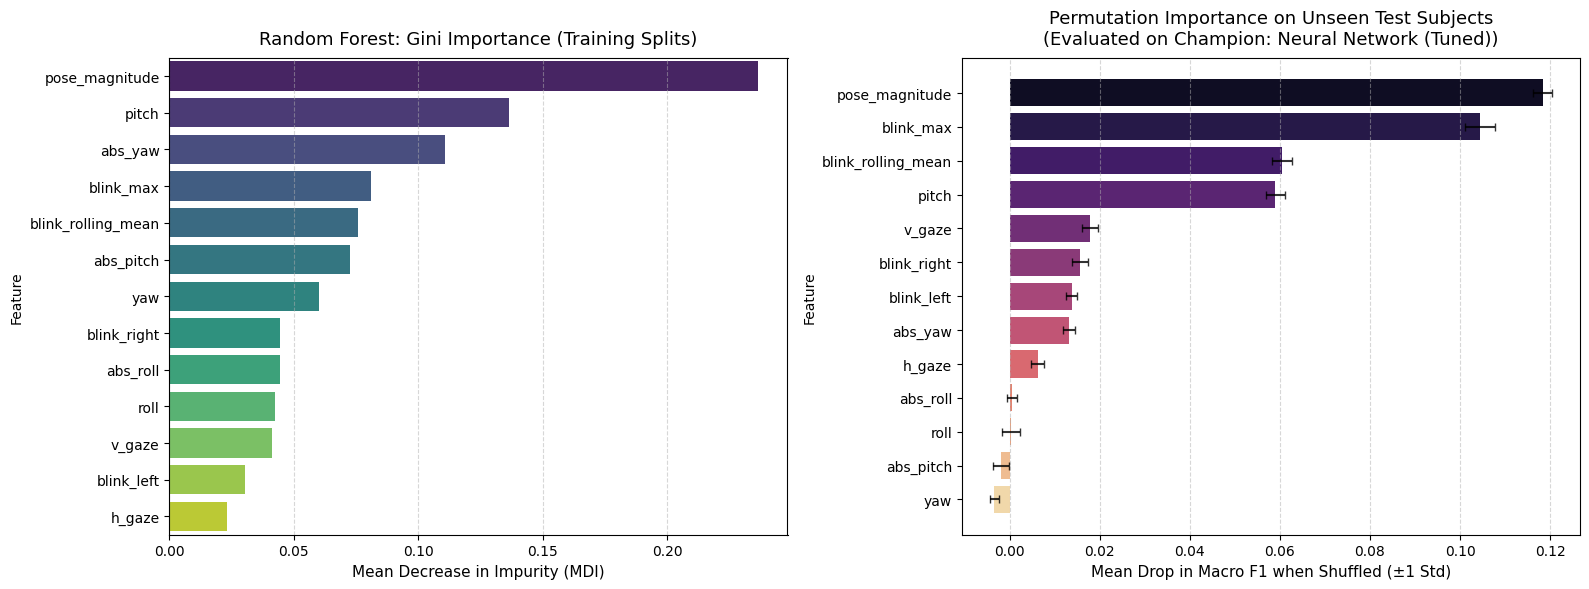

FEATURE IMPORTANCE RANKING (Champion: Neural Network (Tuned))
  01. pose_magnitude       | Drop in F1: +0.1183 (±0.0021)
  02. blink_max            | Drop in F1: +0.1044 (±0.0033)
  03. blink_rolling_mean   | Drop in F1: +0.0605 (±0.0023)
  04. pitch                | Drop in F1: +0.0590 (±0.0021)
  05. v_gaze               | Drop in F1: +0.0178 (±0.0018)
  06. blink_right          | Drop in F1: +0.0156 (±0.0018)
  07. blink_left           | Drop in F1: +0.0138 (±0.0012)
  08. abs_yaw              | Drop in F1: +0.0131 (±0.0014)
  09. h_gaze               | Drop in F1: +0.0062 (±0.0014)
  10. abs_roll             | Drop in F1: +0.0005 (±0.0011)
  11. roll                 | Drop in F1: +0.0003 (±0.0021)
  12. abs_pitch            | Drop in F1: -0.0020 (±0.0018)
  13. yaw                  | Drop in F1: -0.0034 (±0.0010)
  Saved plot PNG -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/figures/feature_importance_comparison.png
  Saved plot PDF -> /content/drive

In [ ]:
# Create figures directory on Google Drive
figures_dir = os.path.join(DRIVE_OUTPUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

# RETRIEVE MODELS (PIPELINE-SAFE)

# Tree Model for Gini / MDI (Random Forest)
tree_model_name = "Random Forest (Tuned)" if "Random Forest (Tuned)" in trained_objects else "Random Forest"
rf_pipe = trained_objects.get(tree_model_name, list(trained_objects.values())[0])
underlying_rf = rf_pipe.named_steps["clf"] if hasattr(rf_pipe, "named_steps") else rf_pipe

# Champion Model for Test Permutation Importance
champion_name = final_df.iloc[0]["Model"] if 'final_df' in globals() else tree_model_name
eval_pipe = trained_objects[champion_name]


# COMPUTE FEATURE IMPORTANCES

# Gini / MDI Importance from Random Forest
rf_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Gini Importance": underlying_rf.feature_importances_
}).sort_values("Gini Importance", ascending=False).reset_index(drop=True)

# Permutation Importance on Held-Out Test Subjects (10 repeats)
perm_col = "Drop in Macro F1"
perm_result = permutation_importance(
    eval_pipe, X_test, y_test,
    n_repeats=10, random_state=RANDOM_SEED, scoring="f1_macro"
)

perm_df = pd.DataFrame({
    "Feature": feature_cols,
    perm_col: perm_result.importances_mean,
    "Std": perm_result.importances_std,
}).sort_values(perm_col, ascending=False).reset_index(drop=True)



# PLOT SIDE-BY-SIDE WITH CONFIDENCE INTERVALS

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Gini Importance (Training Splits)
sns.barplot(
    data=rf_importance, x="Gini Importance", y="Feature",
    order=rf_importance["Feature"],
    hue="Feature", palette="viridis", ax=axes[0], legend=False
)
axes[0].set_title(f"Random Forest: Gini Importance (Training Splits)", fontsize=13, pad=10)
axes[0].set_xlabel("Mean Decrease in Impurity (MDI)", fontsize=11)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Panel B: Permutation Importance on Held-Out Test Set
sns.barplot(
    data=perm_df, x=perm_col, y="Feature",
    order=perm_df["Feature"],
    hue="Feature", palette="magma", ax=axes[1], legend=False
)
# Add error bars representing standard deviation across repeats
axes[1].errorbar(
    x=perm_df[perm_col], y=range(len(perm_df)),
    xerr=perm_df["Std"], fmt='none', c='black', capsize=3, alpha=0.8
)
axes[1].set_title(f"Permutation Importance on Unseen Test Subjects\n(Evaluated on Champion: {champion_name})", fontsize=13, pad=10)
axes[1].set_xlabel("Mean Drop in Macro F1 when Shuffled (±1 Std)", fontsize=11)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save High-Resolution Figures for Presentation/Report
plot_png = os.path.join(figures_dir, "feature_importance_comparison.png")
plot_pdf = os.path.join(figures_dir, "feature_importance_comparison.pdf")
plt.savefig(plot_png, dpi=300, bbox_inches="tight")
plt.savefig(plot_pdf, bbox_inches="tight")
plt.show()

perm_csv_path = os.path.join(figures_dir, "permutation_importance.csv")
perm_df.to_csv(perm_csv_path, index=False)

print(f"FEATURE IMPORTANCE RANKING (Champion: {champion_name})")

for idx, row in perm_df.iterrows():
    print(f"  {idx+1:02d}. {row['Feature']:<20} | Drop in F1: {row[perm_col]:+.4f} (±{row['Std']:.4f})")
print(f"  Saved plot PNG -> {plot_png}")
print(f"  Saved plot PDF -> {plot_pdf}")
print(f"  Saved table CSV -> {perm_csv_path}")

 Confusion Matrix on the Held-Out Test Person

Generating Confusion Matrix for Tuned Champion: 'Neural Network (Tuned)'


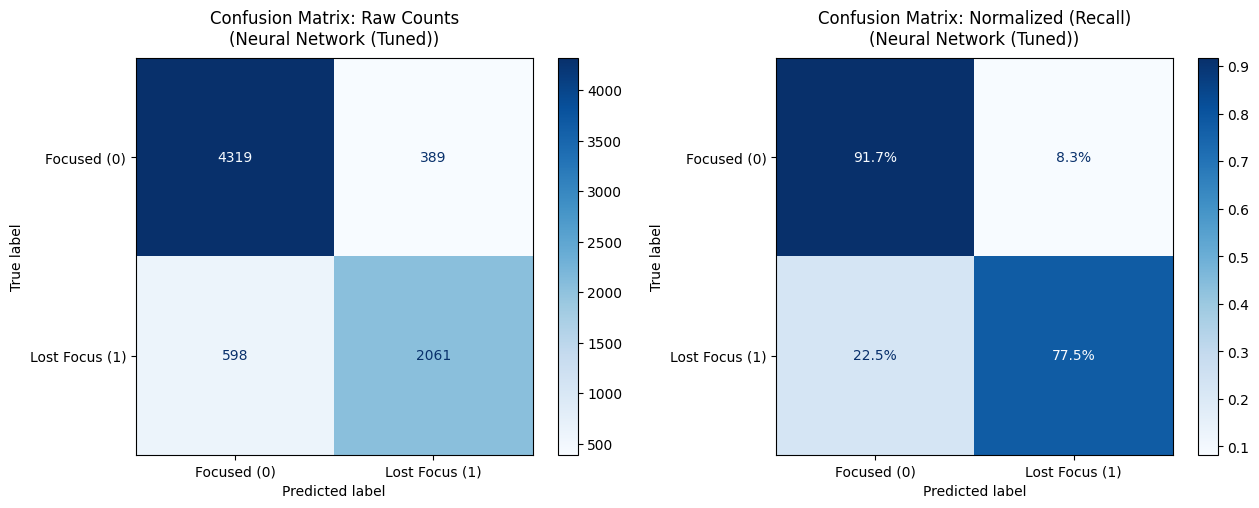


CLASSIFICATION REPORT: Neural Network (Tuned) (Held-Out Test Set)
                precision    recall  f1-score   support

   Focused (0)      0.878     0.917     0.897      4708
Lost Focus (1)      0.841     0.775     0.807      2659

      accuracy                          0.866      7367
     macro avg      0.860     0.846     0.852      7367
  weighted avg      0.865     0.866     0.865      7367

✓ Saved plot PNG -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/figures/confusion_matrix.png
✓ Saved plot PDF -> /content/drive/MyDrive/AIMS Courses/Block 03 - Visual Perception/FocusLens/figures/confusion_matrix.pdf


In [ ]:
# Create figures directory on Google Drive
figures_dir = os.path.join(DRIVE_OUTPUT_DIR, "figures")
os.makedirs(figures_dir, exist_ok=True)

# SELECT CHAMPION MODEL (TUNED OR BASELINE)
if 'final_df' in globals() and 'trained_objects' in globals():
    best_model_name = final_df.iloc[0]["Model"]
    best_clf = trained_objects[best_model_name]
    model_type = "Tuned Champion"
else:
    best_model_name = results_df.iloc[0]["Model"]
    best_clf = trained_models[best_model_name]
    model_type = "Baseline"

print(f"Generating Confusion Matrix for {model_type}: {best_model_name!r}")

# RUN INFERENCE ON UNSEEN HELD-OUT TEST SUBJECTS

# Pipelines automatically apply StandardScaler internally if needed
test_preds = best_clf.predict(X_test)

# Map numeric classes to readable labels
if len(classes) == 2:
    display_labels = ["Focused (0)", "Lost Focus (1)"]
else:
    display_labels = [str(c) for c in classes]



# PLOT SIDE-BY-SIDE CONFUSION MATRICES (RAW COUNTS & NORMALIZED RATES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Raw Sample Counts
disp_raw = ConfusionMatrixDisplay.from_predictions(
    y_test, test_preds,
    display_labels=display_labels,
    cmap="Blues",
    values_format="d",
    ax=axes[0]
)
axes[0].set_title(f"Confusion Matrix: Raw Counts\n({best_model_name})", fontsize=12, pad=10)
axes[0].grid(False)

# Panel B: Normalized by True Class (Recall / Detection Rate)
disp_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, test_preds,
    display_labels=display_labels,
    cmap="Blues",
    normalize="true",
    values_format=".1%",
    ax=axes[1]
)
axes[1].set_title(f"Confusion Matrix: Normalized (Recall)\n({best_model_name})", fontsize=12, pad=10)
axes[1].grid(False)

plt.tight_layout()

# Save High-Resolution Figures for Presentation/Report
cm_png = os.path.join(figures_dir, "confusion_matrix.png")
cm_pdf = os.path.join(figures_dir, "confusion_matrix.pdf")
plt.savefig(cm_png, dpi=300, bbox_inches="tight")
plt.savefig(cm_pdf, bbox_inches="tight")
plt.show()

# PRINT METRIC BREAKDOWN (PRECISION, RECALL, F1)
print("\n" + "="*65)
print(f"CLASSIFICATION REPORT: {best_model_name} (Held-Out Test Set)")
print("="*65)
print(classification_report(y_test, test_preds, target_names=display_labels, digits=3))
print("="*65)
print(f"✓ Saved plot PNG -> {cm_png}")
print(f"✓ Saved plot PDF -> {cm_pdf}")